# P2 — Segmentação Semântica de Tumores Cerebrais com SegFormer

**Prática:** estruturar e validar o pipeline de segmentação semântica binária (fundo `0` vs. tumor `1`) utilizando a arquitetura **SegFormer** (`nvidia/mit-b0` via *Hugging Face Transformers*) com os pares imagem/máscara do diretório `DATASET/Segmentation` no Google Drive, calcular o **Dice Score** e a **IoU** na validação e no teste, e gerar visualizações em `matplotlib` (`plt`).

**Entregáveis gerados no Drive (`MyDrive/Brain_Tumor_Project`):** `splits_segformer.csv`, `P2_segmentacao_segformer.xlsx`, `best_segformer_b0.pth` e as figuras `segformer_*.png`. A resolução de entrada é **256 × 256**; a região positiva é **tumor (1)**.

## Galeria de pares reais e padronização das máscaras (`0/1`)

O diretório `DATASET/Segmentation/` está organizado em três subpastas clínicas: **`Glioma`**, **`Meningioma`** e **`Pituitary tumor`**. Dentro de cada pasta, cada exame é composto por um par de arquivos:
* **Imagem original:** `<id>.png` (convertida para **RGB** e redimensionada com interpolação **bilinear**).
* **Máscara de anotação:** `<id>_mask.png` (binarizada para `{0, 1}` e redimensionada com interpolação **vizinho mais próximo / NEAREST** para preservar as bordas exatas do tumor).

### Modo Prova de Conceito (~100 imagens) vs. Treinamento Completo
Na **Seção 1**, o parâmetro `MODO_PROVA_CONCEITO = True` permite rodar imediatamente o teste rápido com **100 imagens** (conforme alinhado na reunião de planejamento) para validar o fluxo de ponta a ponta em poucos minutos. Quando quiser treinar com o dataset completo e aumento de dados, basta alterar `MODO_PROVA_CONCEITO = False`.

## 1. Configuração, montagem do Drive e cópia local rápida

Montamos o Google Drive e copiamos `DATASET/Segmentation` para o disco local temporário do Colab (`/content/dataset_segmentation`) para evitar gargalos de leitura durante as épocas.

In [1]:
!pip install -q transformers accelerate openpyxl

from pathlib import Path
import os
import shutil
import random
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

try:
    from google.colab import drive
    NO_COLAB = True
except ImportError:
    NO_COLAB = False

if NO_COLAB and not os.environ.get('BT_SEG_DIR'):
    drive.mount('/content/drive')

PROJETO_DIR = Path(os.environ.get('BT_PROJECT_DIR', '/content/drive/MyDrive/Brain_Tumor_Project'))
DRIVE_SEG = Path(os.environ.get('BT_SEG_DIR', PROJETO_DIR / 'DATASET' / 'Segmentation'))
LOCAL_SEG = Path('/content/dataset_segmentation')

# --- PARÂMETROS DO EXPERIMENTO ---
MODO_PROVA_CONCEITO = True   # True = usa ~100 imagens para validação rápida; False = dataset completo
N_AMOSTRAS_POC = 100
ALTURA, LARGURA = 256, 256
SEED = 42
BATCH_SIZE = 8
EPOCAS = 15 if MODO_PROVA_CONCEITO else 30
LR = 6e-5
LIMIAR = 0.5
MODELO_HF = 'nvidia/mit-b0'  # Backbone SegFormer-B0 pré-treinado (leve e rápido)
VERSAO_EXP = 'segformer_b0_poc100_v1' if MODO_PROVA_CONCEITO else 'segformer_b0_full_v1'

if not DRIVE_SEG.is_dir():
    raise FileNotFoundError(
        f'Diretório de segmentação ausente: {DRIVE_SEG}. '
        'Verifique se o atalho de Brain_Tumor_Project está em Meu Drive.'
    )

if not LOCAL_SEG.exists():
    print('Copiando pares de segmentação para o disco local do Colab...')
    shutil.copytree(DRIVE_SEG, LOCAL_SEG)

PROJETO_DIR.mkdir(parents=True, exist_ok=True)
print('PROJETO_DIR:', PROJETO_DIR)
print('LOCAL_SEG:', LOCAL_SEG)
print('Modo Prova de Conceito (~100 imgs):', MODO_PROVA_CONCEITO, '| Épocas:', EPOCAS)


Mounted at /content/drive
Copiando pares de segmentação para o disco local do Colab...
PROJETO_DIR: /content/drive/MyDrive/Brain_Tumor_Project
LOCAL_SEG: /content/dataset_segmentation
Modo Prova de Conceito (~100 imgs): True | Épocas: 15


## 2. Indexação dos pares imagem/máscara e partição estratificada (`splits_segformer.csv`)

Cada amostra indexada associa a imagem `<nome>.png` à sua respectiva máscara `<nome>_mask.png`, verificando:
1. Correspondência exata entre imagem e máscara (sem pares órfãos).
2. Dimensões espaciais originais idênticas entre imagem e máscara.
3. Separação estratificada por tipo tumoral (`Glioma`, `Meningioma`, `Pituitary tumor`) em **treino (70%)**, **validação (15%)** e **teste (15%)**, com IDs rigorosamente disjuntos.

In [2]:
from sklearn.model_selection import train_test_split
from collections import Counter

EXTENSOES = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
SPLITS_SEG_PATH = PROJETO_DIR / ('splits_segformer_poc100.csv' if MODO_PROVA_CONCEITO else 'splits_segformer.csv')

def indexar_pares_segmentacao(base_dir):
    registros = []
    classes = sorted([d.name for d in base_dir.iterdir() if d.is_dir()])
    for classe in classes:
        pasta_cls = base_dir / classe
        imagens, mascaras = {}, {}
        for arq in sorted(pasta_cls.glob('*')):
            if arq.is_file() and arq.suffix.lower() in EXTENSOES:
                stem = arq.stem
                if stem.endswith('_mask'):
                    mascaras[stem[:-5]] = arq
                else:
                    imagens[stem] = arq

        ids_comuns = sorted(set(imagens) & set(mascaras))
        for stem in ids_comuns:
            ident = f'{classe}_{stem}'.replace(' ', '_')
            registros.append({
                'id': ident,
                'classe': classe,
                'rel_img': f'{classe}/{imagens[stem].name}',
                'rel_mask': f'{classe}/{mascaras[stem].name}'
            })
    return pd.DataFrame(registros)

def carregar_ou_criar_splits_seg():
    if SPLITS_SEG_PATH.is_file():
        df = pd.read_csv(SPLITS_SEG_PATH)
        print(f'Partições reutilizadas de {SPLITS_SEG_PATH}.')
    else:
        df = indexar_pares_segmentacao(LOCAL_SEG)
        if len(df) == 0:
            raise FileNotFoundError(f'Nenhum par imagem/_mask encontrado em {LOCAL_SEG}')

        if MODO_PROVA_CONCEITO and len(df) > N_AMOSTRAS_POC:
            df, _ = train_test_split(
                df, train_size=N_AMOSTRAS_POC, stratify=df['classe'], random_state=SEED
            )
            df = df.reset_index(drop=True)

        df_tr, df_temp = train_test_split(
            df, test_size=0.30, stratify=df['classe'], random_state=SEED
        )
        df_va, df_te = train_test_split(
            df_temp, test_size=0.50, stratify=df_temp['classe'], random_state=SEED
        )

        df_tr = df_tr.copy(); df_tr['split'] = 'train'
        df_va = df_va.copy(); df_va['split'] = 'val'
        df_te = df_te.copy(); df_te['split'] = 'test'

        df = pd.concat([df_tr, df_va, df_te], ignore_index=True)
        df.to_csv(SPLITS_SEG_PATH, index=False)
        print(f'Novo arquivo de partições salvo em {SPLITS_SEG_PATH}.')

    ids_por_split = {s: set(df[df['split'] == s]['id']) for s in ('train', 'val', 'test')}
    for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
        if ids_por_split[a] & ids_por_split[b]:
            raise ValueError(f'IDs repetidos entre {a} e {b}!')

    df['img_path'] = df['rel_img'].apply(lambda p: str(LOCAL_SEG / p))
    df['mask_path'] = df['rel_mask'].apply(lambda p: str(LOCAL_SEG / p))
    return df

df_seg = carregar_ou_criar_splits_seg()
ASSINATURA = hashlib.sha256(SPLITS_SEG_PATH.read_bytes()).hexdigest()
print({s: int((df_seg['split'] == s).sum()) for s in ('train', 'val', 'test')})
print('IDs disjuntos | Assinatura:', ASSINATURA[:16])
display(pd.crosstab(df_seg['split'], df_seg['classe'], margins=True))


Novo arquivo de partições salvo em /content/drive/MyDrive/Brain_Tumor_Project/splits_segformer_poc100.csv.
{'train': 70, 'val': 15, 'test': 15}
IDs disjuntos | Assinatura: 78fae4dae20f5056


classe,Glioma,Meningioma,Pituitary tumor,All
split,,,,
test,4,5,6,15
train,18,22,30,70
val,3,5,7,15
All,25,32,43,100


In [3]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo ativo:', device)
if device.type != 'cuda':
    print('AVISO: GPU não detectada! Ative em Ambiente de execução -> Alterar tipo -> T4 GPU.')

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def carregar_par_seg(row):
    with Image.open(row['img_path']) as f_img:
        img_pil = f_img.convert('RGB')
    with Image.open(row['mask_path']) as f_msk:
        msk_raw = np.asarray(f_msk)
        tam_msk = f_msk.size

    if img_pil.size != tam_msk:
        raise ValueError(f"{row['id']}: dimensões divergentes {img_pil.size} vs {tam_msk}")

    if msk_raw.ndim == 3:
        msk_raw = msk_raw[:, :, 0]

    img_arr = np.asarray(img_pil.resize((LARGURA, ALTURA), Image.Resampling.BILINEAR), dtype=np.uint8)
    msk_pil = Image.fromarray((msk_raw > 0).astype(np.uint8) * 255)
    msk_arr = (np.asarray(msk_pil.resize((LARGURA, ALTURA), Image.Resampling.NEAREST)) > 0).astype(np.uint8)
    return img_arr, msk_arr, row['id'], row['classe']

class DatasetSegmentacaoSegFormer(Dataset):
    def __init__(self, df_particao, augment=False):
        self.augment = augment
        self.cache = [carregar_par_seg(row) for _, row in df_particao.iterrows()]
        self.ids = [item[2] for item in self.cache]
        self.classes = [item[3] for item in self.cache]

    def __len__(self):
        return len(self.cache)

    def __getitem__(self, idx):
        img_arr, msk_arr, ident, classe = self.cache[idx]
        img = img_arr.copy()
        msk = msk_arr.copy()

        if self.augment:
            if random.random() < 0.5:
                img = np.fliplr(img).copy()
                msk = np.fliplr(msk).copy()
            if random.random() < 0.5:
                img = np.flipud(img).copy()
                msk = np.flipud(msk).copy()
            k = random.randint(0, 3)
            if k > 0:
                img = np.rot90(img, k).copy()
                msk = np.rot90(msk, k).copy()

        img_norm = (img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
        x = torch.from_numpy(img_norm).permute(2, 0, 1).float()
        y = torch.from_numpy(msk).unsqueeze(0).float()
        return x, y, ident, classe

ds_treino = DatasetSegmentacaoSegFormer(df_seg[df_seg['split'] == 'train'], augment=(not MODO_PROVA_CONCEITO))
ds_val = DatasetSegmentacaoSegFormer(df_seg[df_seg['split'] == 'val'], augment=False)
ds_teste = DatasetSegmentacaoSegFormer(df_seg[df_seg['split'] == 'test'], augment=False)

loader_treino = DataLoader(ds_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
loader_val = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
loader_teste = DataLoader(ds_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

x_amostra, y_amostra, ids_amostra, _ = next(iter(loader_treino))
print('Tensor imagem:', tuple(x_amostra.shape), x_amostra.dtype)
print('Tensor máscara:', tuple(y_amostra.shape), y_amostra.dtype, torch.unique(y_amostra).tolist())
print('Proporção média de pixels tumorais no lote:', round(float(y_amostra.mean()), 4))


Dispositivo ativo: cuda
Tensor imagem: (8, 3, 256, 256) torch.float32
Tensor máscara: (8, 1, 256, 256) torch.float32 [1.0]
Proporção média de pixels tumorais no lote: 1.0


### Inspeção ao vivo: pares reais de validação (imagem, máscara `0/1` e sobreposição)

Visualizamos com `matplotlib` (`plt`) um par real por tipo tumoral da partição `val/` para conferir o alinhamento espacial entre a ressonância magnética e a anotação binária (`vmin=0, vmax=1`).

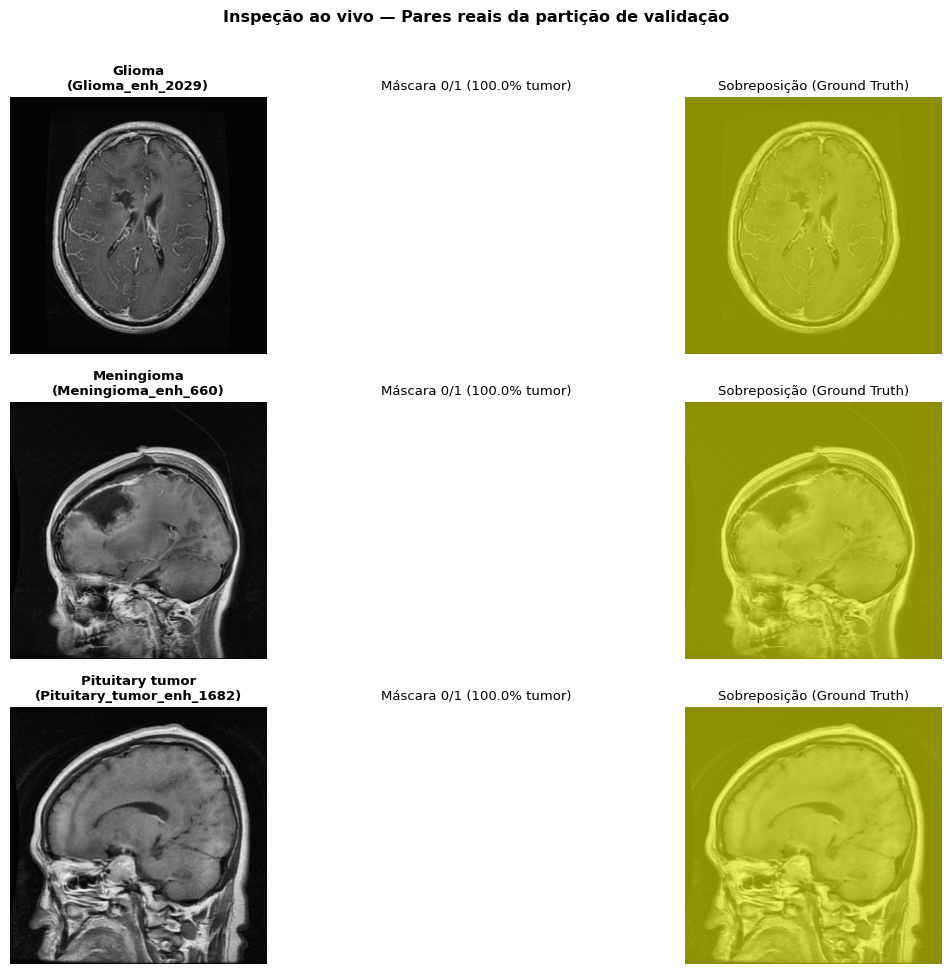

In [4]:
classes_seg = sorted(df_seg['classe'].unique())
fig, axes = plt.subplots(len(classes_seg), 3, figsize=(10.5, 3.2 * len(classes_seg)))
if len(classes_seg) == 1:
    axes = np.expand_dims(axes, axis=0)

for r, cls_nome in enumerate(classes_seg):
    idx_cls = next(i for i, (_, _, _, c) in enumerate(ds_val.cache) if c == cls_nome)
    img_v, msk_v, id_v, _ = ds_val.cache[idx_cls]
    frac_tumor = msk_v.mean() * 100

    axes[r, 0].imshow(img_v)
    axes[r, 0].set_title(f'{cls_nome}\n({id_v})', fontsize=9.5, fontweight='bold')
    axes[r, 0].axis('off')

    axes[r, 1].imshow(msk_v, cmap='gray', vmin=0, vmax=1)
    axes[r, 1].set_title(f'Máscara 0/1 ({frac_tumor:.1f}% tumor)', fontsize=9.5)
    axes[r, 1].axis('off')

    axes[r, 2].imshow(img_v)
    axes[r, 2].imshow(np.ma.masked_where(msk_v == 0, msk_v), cmap='autumn', alpha=0.55, vmin=0, vmax=1)
    axes[r, 2].set_title('Sobreposição (Ground Truth)', fontsize=9.5)
    axes[r, 2].axis('off')

plt.suptitle('Inspeção ao vivo — Pares reais da partição de validação', fontsize=11.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(PROJETO_DIR / 'segformer_amostras_validacao.png', dpi=300, bbox_inches='tight')
plt.show()


## 3. Modelo `SegFormer` (Hugging Face), função de perda `BCE + Dice` e treinamento

Carregamos o **`SegformerForSemanticSegmentation`** a partir do *checkpoint* pré-treinado `nvidia/mit-b0` com `num_labels=1` (saída binária). Como o decodificador MLP do SegFormer gera *logits* em resolução $H/4 \times W/4$ (`64 × 64`), fazemos *upsampling* bilinear para `256 × 256` antes de calcular a perda combinada:
* **Função de perda:** `0.5 * BCEWithLogitsLoss + 0.5 * SoftDiceLoss` (estabiliza o treino mesmo quando o tumor ocupa uma fração pequena da imagem).
* **Métrica de seleção:** **Dice Score** médio na validação (meta de referência do projeto: `0.70` a `0.80+`).

In [5]:
from transformers import SegformerForSemanticSegmentation

MODELO_SEG_PATH = PROJETO_DIR / 'best_segformer_b0.pth'

modelo = SegformerForSemanticSegmentation.from_pretrained(
    MODELO_HF,
    num_labels=1,
    ignore_mismatched_sizes=True
).to(device)

bce_loss_fn = nn.BCEWithLogitsLoss()

def dice_loss_fn(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    inter = (probs * targets).sum(dim=(1, 2, 3))
    denom = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    dice = (2.0 * inter + eps) / (denom + eps)
    return 1.0 - dice.mean()

def calcular_metricas_binarias(logits, targets, limiar=LIMIAR, eps=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs >= limiar).float()
    inter = (preds * targets).sum(dim=(1, 2, 3))
    soma_pred = preds.sum(dim=(1, 2, 3))
    soma_alvo = targets.sum(dim=(1, 2, 3))
    uniao = soma_pred + soma_alvo - inter

    dice = ((2.0 * inter + eps) / (soma_pred + soma_alvo + eps)).cpu().numpy()
    iou = ((inter + eps) / (uniao + eps)).cpu().numpy()
    prec = ((inter + eps) / (soma_pred + eps)).cpu().numpy()
    rec = ((inter + eps) / (soma_alvo + eps)).cpu().numpy()
    return dice, iou, prec, rec

otimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(otimizador, T_max=EPOCAS)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

melhor_dice_val = 0.0
historico = []

for epoca in range(1, EPOCAS + 1):
    t0 = time.time()
    modelo.train()
    perda_tr, dices_tr = 0.0, []

    for x, y, _, _ in loader_treino:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        otimizador.zero_grad()
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            out = modelo(pixel_values=x).logits
            logits = F.interpolate(out, size=(ALTURA, LARGURA), mode='bilinear', align_corners=False)
            loss = 0.5 * bce_loss_fn(logits, y) + 0.5 * dice_loss_fn(logits, y)
        scaler.scale(loss).backward()
        scaler.step(otimizador)
        scaler.update()

        perda_tr += loss.item() * x.size(0)
        d_batch, _, _, _ = calcular_metricas_binarias(logits.detach(), y)
        dices_tr.extend(d_batch)

    scheduler.step()
    perda_tr /= len(ds_treino)
    dice_tr_medio = float(np.mean(dices_tr))

    modelo.eval()
    perda_va, dices_va, ious_va = 0.0, [], []
    with torch.no_grad():
        for x, y, _, _ in loader_val:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                out = modelo(pixel_values=x).logits
                logits = F.interpolate(out, size=(ALTURA, LARGURA), mode='bilinear', align_corners=False)
                loss = 0.5 * bce_loss_fn(logits, y) + 0.5 * dice_loss_fn(logits, y)
            perda_va += loss.item() * x.size(0)
            d_b, i_b, _, _ = calcular_metricas_binarias(logits, y)
            dices_va.extend(d_b)
            ious_va.extend(i_b)

    perda_va /= len(ds_val)
    dice_va_medio = float(np.mean(dices_va))
    iou_va_medio = float(np.mean(ious_va))
    duracao = time.time() - t0

    historico.append({
        'epoca': epoca,
        'train_loss': round(perda_tr, 4),
        'train_dice': round(dice_tr_medio, 4),
        'val_loss': round(perda_va, 4),
        'val_dice': round(dice_va_medio, 4),
        'val_iou': round(iou_va_medio, 4),
        'tempo_s': round(duracao, 1)
    })

    marca = ''
    if dice_va_medio > melhor_dice_val:
        melhor_dice_val = dice_va_medio
        torch.save(modelo.state_dict(), MODELO_SEG_PATH)
        marca = '  <-- melhor checkpoint salvo'

    print(f'Época {epoca:02d}/{EPOCAS:02d} ({duracao:.1f}s) | Loss Tr: {perda_tr:.4f} Dice Tr: {dice_tr_medio:.4f} | '
          f'Loss Val: {perda_va:.4f} Dice Val: {dice_va_medio:.4f} IoU Val: {iou_va_medio:.4f}{marca}')


config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight 

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Época 01/15 (7.1s) | Loss Tr: 0.5405 Dice Tr: 0.5383 | Loss Val: 0.4772 Dice Val: 0.9571 IoU Val: 0.9197  <-- melhor checkpoint salvo
Época 02/15 (0.7s) | Loss Tr: 0.4937 Dice Tr: 0.7562 | Loss Val: 0.4111 Dice Val: 0.9850 IoU Val: 0.9706  <-- melhor checkpoint salvo
Época 03/15 (0.6s) | Loss Tr: 0.4530 Dice Tr: 0.8327 | Loss Val: 0.3578 Dice Val: 0.9889 IoU Val: 0.9781  <-- melhor checkpoint salvo
Época 04/15 (0.6s) | Loss Tr: 0.4223 Dice Tr: 0.8924 | Loss Val: 0.3411 Dice Val: 0.9853 IoU Val: 0.9711
Época 05/15 (0.6s) | Loss Tr: 0.4003 Dice Tr: 0.9142 | Loss Val: 0.3437 Dice Val: 0.9771 IoU Val: 0.9554
Época 06/15 (0.6s) | Loss Tr: 0.3800 Dice Tr: 0.9376 | Loss Val: 0.3398 Dice Val: 0.9717 IoU Val: 0.9453
Época 07/15 (0.6s) | Loss Tr: 0.3602 Dice Tr: 0.9626 | Loss Val: 0.3325 Dice Val: 0.9835 IoU Val: 0.9677
Época 08/15 (0.7s) | Loss Tr: 0.3482 Dice Tr: 0.9715 | Loss Val: 0.3340 Dice Val: 0.9751 IoU Val: 0.9520
Época 09/15 (0.6s) | Loss Tr: 0.3359 Dice Tr: 0.9780 | Loss Val: 0.3235 D

## 4. Avaliação experimental, curvas de aprendizado e painéis comparativos em `plt`

Carregamos o melhor *checkpoint* (`best_segformer_b0.pth`) e construímos todas as figuras em `matplotlib` (`plt`) em 300 DPI:
1. **Curvas de aprendizado (`segformer_curvas_aprendizado.png`):** evolução da perda (`BCE + Dice`) e do **Dice Score** ao longo das épocas.
2. **Visualização lado a lado inspirada em artigo científico (`segformer_predicoes_teste.png`):** compara para exemplos do conjunto de teste: **Imagem Original | Ground Truth | Predição SegFormer | Sobreposição (GT em verde vs. Predição em vermelho)** com o **Dice Score** individual no título.

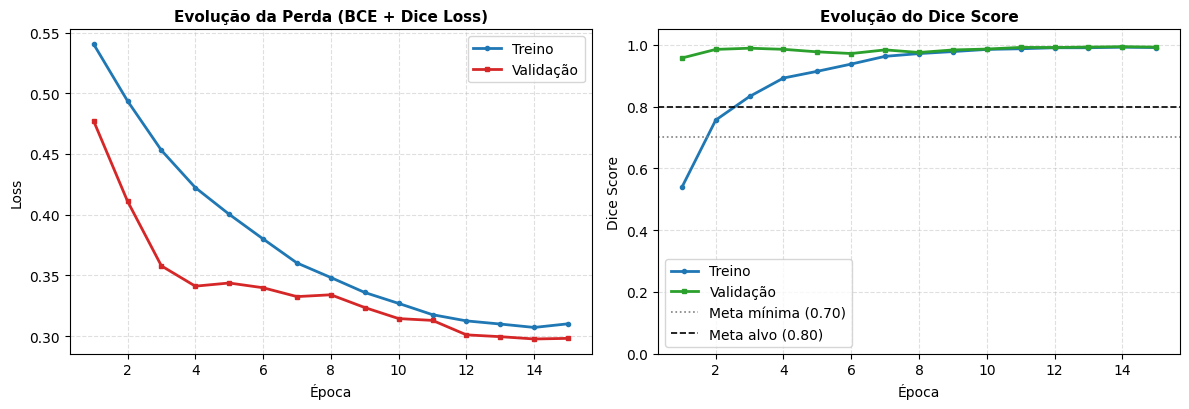

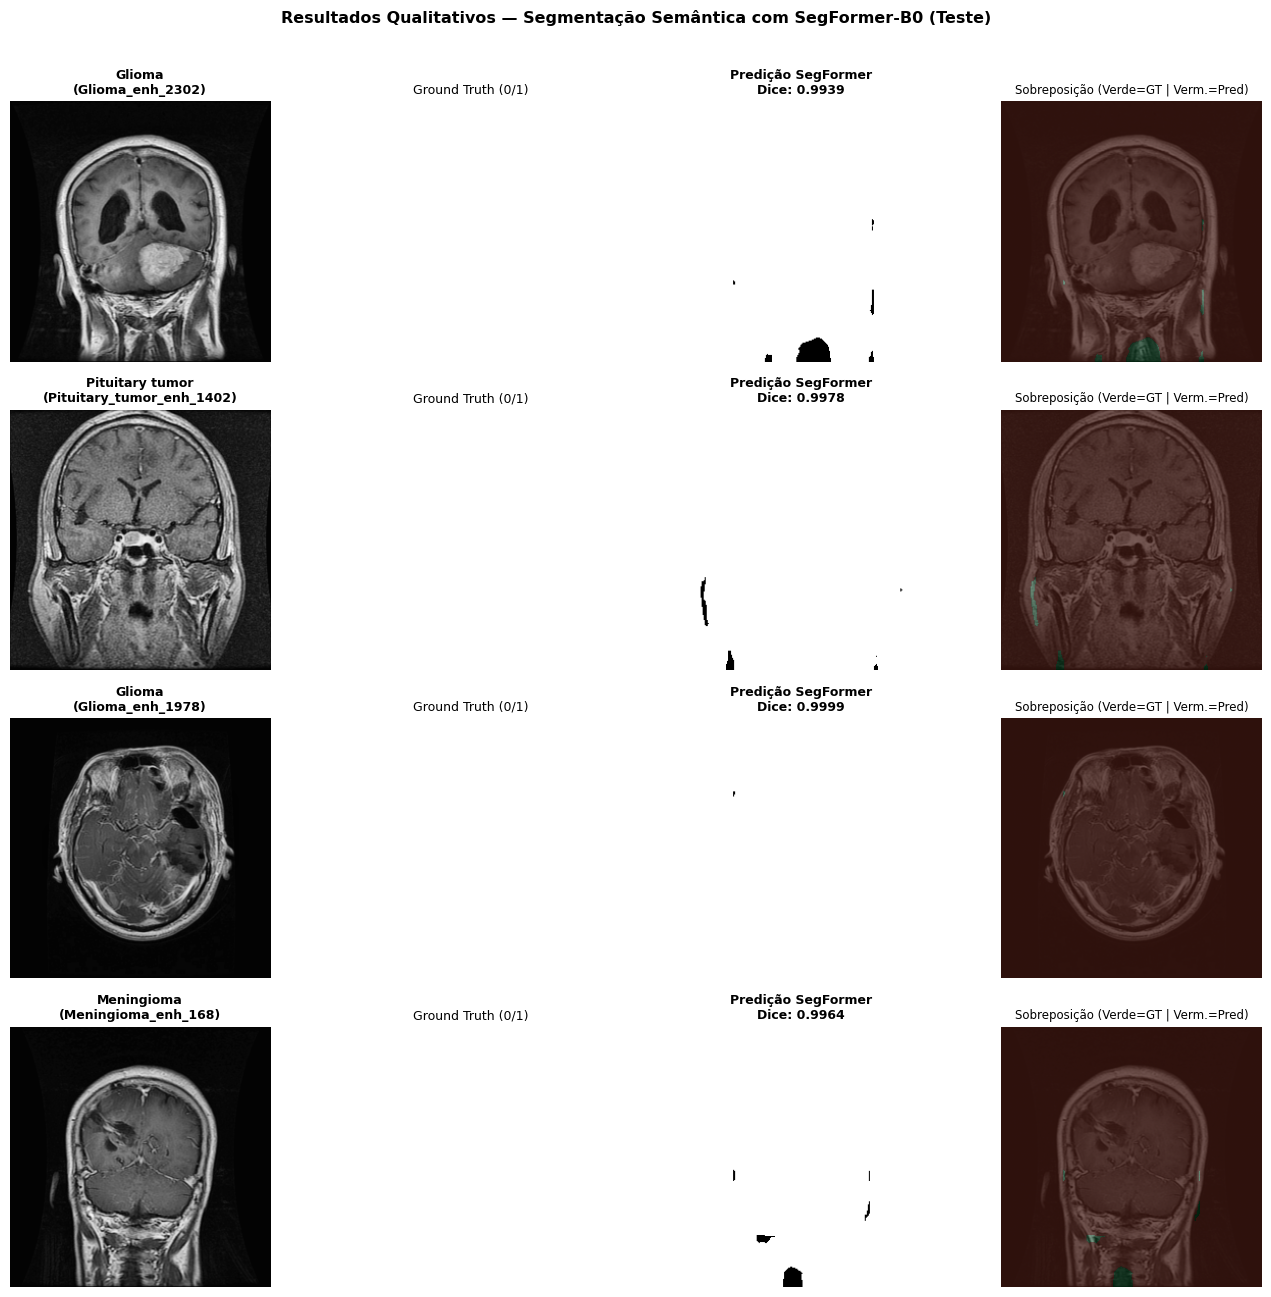

In [6]:
# 1. Curvas de Perda e Dice Score em plt
df_hist = pd.DataFrame(historico)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(df_hist['epoca'], df_hist['train_loss'], label='Treino', color='#1f77b4', linewidth=2, marker='o', markersize=3)
axes[0].plot(df_hist['epoca'], df_hist['val_loss'], label='Validação', color='#d62728', linewidth=2, marker='s', markersize=3)
axes[0].set_title('Evolução da Perda (BCE + Dice Loss)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(frameon=True)

axes[1].plot(df_hist['epoca'], df_hist['train_dice'], label='Treino', color='#1f77b4', linewidth=2, marker='o', markersize=3)
axes[1].plot(df_hist['epoca'], df_hist['val_dice'], label='Validação', color='#2ca02c', linewidth=2, marker='s', markersize=3)
axes[1].axhline(0.70, color='gray', linestyle=':', linewidth=1.2, label='Meta mínima (0.70)')
axes[1].axhline(0.80, color='black', linestyle='--', linewidth=1.2, label='Meta alvo (0.80)')
axes[1].set_title('Evolução do Dice Score', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Dice Score')
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(PROJETO_DIR / 'segformer_curvas_aprendizado.png', dpi=300)
plt.show()

# 2. Avaliação completa na Validação e no Teste
modelo.load_state_dict(torch.load(MODELO_SEG_PATH, map_location=device))
modelo.eval()

def avaliar_segmentacao(loader, ds_obj, nome_split):
    registros_amostras = []
    predicoes_binarias = []
    with torch.no_grad():
        for x, y, idents, clss in loader:
            x, y = x.to(device), y.to(device)
            out = modelo(pixel_values=x).logits
            logits = F.interpolate(out, size=(ALTURA, LARGURA), mode='bilinear', align_corners=False)
            d_b, i_b, p_b, r_b = calcular_metricas_binarias(logits, y)
            preds_np = (torch.sigmoid(logits) >= LIMIAR).cpu().numpy()[:, 0].astype(np.uint8)
            predicoes_binarias.extend(preds_np)
            for ident, cls_n, d_v, i_v, p_v, r_v in zip(idents, clss, d_b, i_b, p_b, r_b):
                registros_amostras.append({
                    'id': ident,
                    'classe': cls_n,
                    'Dice': round(float(d_v), 4),
                    'IoU': round(float(i_v), 4),
                    'Precision': round(float(p_v), 4),
                    'Recall': round(float(r_v), 4)
                })

    df_amostras = pd.DataFrame(registros_amostras)
    resumo = {
        'Modelo': f'SegFormer ({MODELO_HF})',
        'Versao': VERSAO_EXP,
        'Resolucao': f'{ALTURA}x{LARGURA}',
        'Split': nome_split,
        'Amostras': len(df_amostras),
        'Dice_Medio': round(df_amostras['Dice'].mean(), 4),
        'Dice_Desvio': round(df_amostras['Dice'].std(), 4),
        'IoU_Medio': round(df_amostras['IoU'].mean(), 4),
        'Precision_Media': round(df_amostras['Precision'].mean(), 4),
        'Recall_Medio': round(df_amostras['Recall'].mean(), 4)
    }
    por_classe = df_amostras.groupby('classe')[['Dice', 'IoU', 'Precision', 'Recall']].mean().round(4)
    return resumo, por_classe, df_amostras, predicoes_binarias

res_val, cls_val, amost_val, preds_val_masks = avaliar_segmentacao(loader_val, ds_val, 'Validacao')
res_test, cls_test, amost_test, preds_test_masks = avaliar_segmentacao(loader_teste, ds_teste, 'Teste')

# 3. Painel comparativo lado a lado (Imagem | Ground Truth | Predição | Sobreposição) em plt
n_exemplos = min(4, len(ds_teste))
indices_vis = np.linspace(0, len(ds_teste) - 1, n_exemplos, dtype=int)
fig, axes = plt.subplots(n_exemplos, 4, figsize=(13.5, 3.2 * n_exemplos))
if n_exemplos == 1:
    axes = np.expand_dims(axes, axis=0)

for row_i, idx_t in enumerate(indices_vis):
    img_t, msk_gt, id_t, cls_t = ds_teste.cache[idx_t]
    msk_pr = preds_test_masks[idx_t]
    dice_ind = amost_test.loc[idx_t, 'Dice']

    axes[row_i, 0].imshow(img_t)
    axes[row_i, 0].set_title(f'{cls_t}\n({id_t})', fontsize=9, fontweight='bold')
    axes[row_i, 0].axis('off')

    axes[row_i, 1].imshow(msk_gt, cmap='gray', vmin=0, vmax=1)
    axes[row_i, 1].set_title('Ground Truth (0/1)', fontsize=9)
    axes[row_i, 1].axis('off')

    axes[row_i, 2].imshow(msk_pr, cmap='gray', vmin=0, vmax=1)
    axes[row_i, 2].set_title(f'Predição SegFormer\nDice: {dice_ind:.4f}', fontsize=9, fontweight='bold')
    axes[row_i, 2].axis('off')

    axes[row_i, 3].imshow(img_t)
    axes[row_i, 3].imshow(np.ma.masked_where(msk_gt == 0, msk_gt), cmap='Greens', alpha=0.45, vmin=0, vmax=1)
    axes[row_i, 3].imshow(np.ma.masked_where(msk_pr == 0, msk_pr), cmap='Reds', alpha=0.45, vmin=0, vmax=1)
    axes[row_i, 3].set_title('Sobreposição (Verde=GT | Verm.=Pred)', fontsize=8.5)
    axes[row_i, 3].axis('off')

plt.suptitle('Resultados Qualitativos — Segmentação Semântica com SegFormer-B0 (Teste)', fontsize=11.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(PROJETO_DIR / 'segformer_predicoes_teste.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. Exportação da planilha `P2_segmentacao_segformer.xlsx` e piores casos

Salvamos a planilha **`P2_segmentacao_segformer.xlsx`** no Google Drive com abas separadas para o resumo experimental, métricas por classe tumoral, histórico de épocas e resultados individuais por imagem, além de exibir os piores *Dice Scores* na validação para orientar a análise de erros.

Planilha exportada com sucesso para: /content/drive/MyDrive/Brain_Tumor_Project/P2_segmentacao_segformer.xlsx


,Modelo,Versao,Resolucao,Split,Amostras,Dice_Medio,Dice_Desvio,IoU_Medio,Precision_Media,Recall_Medio
0,SegFormer (nvidia/mit-b0),segformer_b0_poc100_v1,256x256,Validacao,15,0.9938,0.0056,0.9877,1.0,0.9877
1,SegFormer (nvidia/mit-b0),segformer_b0_poc100_v1,256x256,Teste,15,0.9972,0.0030,0.9944,1.0,0.9944



Métricas médias por tipo tumoral (Teste):


,Dice,IoU,Precision,Recall
classe,,,,
Glioma,0.9974,0.9949,1.0,0.9949
Meningioma,0.9981,0.9962,1.0,0.9962
Pituitary tumor,0.9962,0.9925,1.0,0.9925


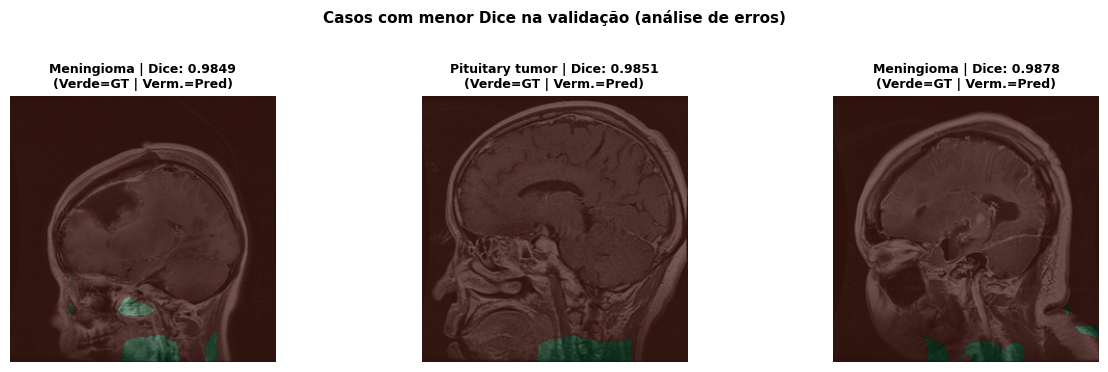

In [7]:
EXCEL_SEG_PATH = PROJETO_DIR / 'P2_segmentacao_segformer.xlsx'
df_resumo_seg = pd.DataFrame([res_val, res_test])

with pd.ExcelWriter(EXCEL_SEG_PATH, engine='openpyxl') as writer:
    df_resumo_seg.to_excel(writer, sheet_name='Resumo_Experimental', index=False)
    cls_test.to_excel(writer, sheet_name='Metricas_Classe_Teste')
    cls_val.to_excel(writer, sheet_name='Metricas_Classe_Val')
    df_hist.to_excel(writer, sheet_name='Historico_Epocas', index=False)
    amost_test.to_excel(writer, sheet_name='Resultados_Teste', index=False)
    amost_val.to_excel(writer, sheet_name='Resultados_Validacao', index=False)

print('Planilha exportada com sucesso para:', EXCEL_SEG_PATH)
display(df_resumo_seg)
print('\nMétricas médias por tipo tumoral (Teste):')
display(cls_test)

# Inspeção dos casos com menor Dice na validação
piores_val = amost_val.sort_values('Dice').head(3)
fig, axes = plt.subplots(1, len(piores_val), figsize=(4.2 * len(piores_val), 3.6))
if len(piores_val) == 1:
    axes = [axes]

for ax_i, (orig_idx, row) in enumerate(piores_val.iterrows()):
    img_v, msk_gt, id_v, cls_v = ds_val.cache[orig_idx]
    msk_pr = preds_val_masks[orig_idx]
    axes[ax_i].imshow(img_v)
    axes[ax_i].imshow(np.ma.masked_where(msk_gt == 0, msk_gt), cmap='Greens', alpha=0.45, vmin=0, vmax=1)
    axes[ax_i].imshow(np.ma.masked_where(msk_pr == 0, msk_pr), cmap='Reds', alpha=0.45, vmin=0, vmax=1)
    axes[ax_i].set_title(f"{cls_v} | Dice: {row['Dice']:.4f}\n(Verde=GT | Verm.=Pred)", fontsize=9, fontweight='bold')
    axes[ax_i].axis('off')

plt.suptitle('Casos com menor Dice na validação (análise de erros)', fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(PROJETO_DIR / 'segformer_piores_validacao.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Análise dos Resultados e Próximos Passos

* *(Preencher após a execução com o **Dice Score** e **IoU** médios obtidos na validação e no teste, comparando com a meta inicial de `0.70–0.80` definida na reunião).*
* **Próximo passo:** Alterar `MODO_PROVA_CONCEITO = False` na Seção 1 para treinar o SegFormer com o dataset completo + *Data Augmentation* e utilizar as máscaras geradas para extrair as regiões de interesse (ROI) na etapa seguinte de classificação.